# Лабораторная работа №4
## Аналитика как конкурентное преимущество

**Задание 1.** Комплексная система мультиплеерной аналитики «Multiplayer Balance & Matchmaking Insights»: качество матчмейкинга, баланс карт, антифрод.
**Задание 2.** Интерактивный экран «Матрица соревновательного баланса персонажей» (Pick Rate vs Win Rate).

Данные — синтетические логи соревновательного шутера 5v5, сгенерированные скриптом `src/generate_data.py` с заложенными «скрытыми аномалиями» для проверки алгоритмов.

## Задание 1. Шаг 1. Проектирование хранилища и загрузка данных

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binomtest
import plotly.express as px
import plotly.graph_objects as go

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
REPORTS = '../reports'

In [2]:
# Схема данных: ID — строки, MMR — целые, метрики эффективности — дробные
matches_df = pd.read_csv('../data/matches.csv', parse_dates=['match_date'], keep_default_na=False,
                         dtype={'match_id': 'string', 'map_id': 'string', 'server_region': 'string',
                                'winning_team': 'string', 'duration_sec': 'int64', 'queue_time_sec': 'float64'})
players_df = pd.read_csv('../data/player_stats.csv',
                         dtype={'match_id': 'string', 'player_id': 'string', 'team_side': 'string',
                                'hero_id': 'string', 'weapon_id': 'string', 'kills': 'int64', 'deaths': 'int64',
                                'assists': 'int64', 'mmr_before': 'int64', 'mmr_after': 'int64', 'ping': 'int64'})
reports_df = pd.read_csv('../data/reports.csv', dtype='string')

for name, df in [('matches_df', matches_df), ('players_df', players_df), ('reports_df', reports_df)]:
    print(f"{name}: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
print()
players_df.info()

matches_df: 3,000 строк × 7 столбцов
players_df: 30,000 строк × 11 столбцов
reports_df: 2,319 строк × 4 столбцов

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   match_id    30000 non-null  string
 1   player_id   30000 non-null  string
 2   team_side   30000 non-null  string
 3   hero_id     30000 non-null  string
 4   weapon_id   30000 non-null  string
 5   kills       30000 non-null  int64 
 6   deaths      30000 non-null  int64 
 7   assists     30000 non-null  int64 
 8   mmr_before  30000 non-null  int64 
 9   mmr_after   30000 non-null  int64 
 10  ping        30000 non-null  int64 
dtypes: int64(6), string(5)
memory usage: 2.5 MB


In [3]:
display(matches_df.head(3))
display(players_df.head(3))
display(reports_df.head(3))

# Проверки целостности реляционной структуры
assert matches_df['match_id'].is_unique
assert players_df.groupby('match_id').size().eq(10).all(), 'в каждом матче должно быть 10 игроков'
assert players_df.groupby(['match_id', 'team_side']).size().eq(5).all(), 'команды 5 на 5'
assert players_df['match_id'].isin(matches_df['match_id']).all()
assert reports_df['match_id'].isin(matches_df['match_id']).all()
print("Целостность: 10 игроков на матч, команды 5v5, все ссылки match_id корректны")
print(f"Уникальных игроков: {players_df['player_id'].nunique():,}; "
      f"период: {matches_df['match_date'].min().date()} — {matches_df['match_date'].max().date()}")
print("Жалобы по причинам:", reports_df['reason'].value_counts().to_dict())

,match_id,map_id,duration_sec,server_region,winning_team,queue_time_sec,match_date
0,MATCH_00000,De_Dust2,1375,EU,Defense,112.5,2026-09-06 11:37:00
1,MATCH_00001,De_Inferno,1702,EU,Attack,132.2,2026-09-12 00:49:00
2,MATCH_00002,De_Mirage,1671,ASIA,Defense,75.2,2026-09-06 17:00:00


,match_id,player_id,team_side,hero_id,weapon_id,kills,deaths,assists,mmr_before,mmr_after,ping
0,MATCH_00000,PLAYER_00599,Attack,Hero_9,SMG_MP9,23,16,11,2546,2518,77
1,MATCH_00000,PLAYER_00525,Attack,Hero_8,SMG_MP9,13,19,5,2334,2308,29
2,MATCH_00000,PLAYER_01570,Attack,Hero_20,Shotgun_Nova,7,21,4,2096,2070,72


,match_id,reporter_id,reported_id,reason
0,MATCH_00000,PLAYER_01923,PLAYER_00074,cheating
1,MATCH_00000,PLAYER_00529,PLAYER_00074,cheating
2,MATCH_00000,PLAYER_01384,PLAYER_00599,toxicity


Целостность: 10 игроков на матч, команды 5v5, все ссылки match_id корректны
Уникальных игроков: 1,953; период: 2026-09-01 — 2026-09-14
Жалобы по причинам: {'cheating': 1294, 'toxicity': 859, 'afk': 166}


## Шаг 2. Модуль А: качество матчмейкинга
* **ΔMMR** = |Mean(MMR_Attack) − Mean(MMR_Defense)| — разница средней силы команд;
* **StDev(MMR)** внутри команды — признак «паровоза» (новичок с хардкорщиками);
* **Unfair_Match** — флаг матчей с ΔMMR > 250.

In [4]:
team_mmr = (players_df.groupby(['match_id', 'team_side'])['mmr_before']
            .agg(['mean', 'std']).unstack())
team_mmr.columns = [f'{stat}_{side}' for stat, side in team_mmr.columns]
team_mmr = team_mmr.rename(columns={'mean_Attack': 'mmr_attack', 'mean_Defense': 'mmr_defense',
                                    'std_Attack': 'std_attack', 'std_Defense': 'std_defense'}).reset_index()
team_mmr['mmr_delta'] = (team_mmr['mmr_attack'] - team_mmr['mmr_defense']).abs()
team_mmr['max_team_std'] = team_mmr[['std_attack', 'std_defense']].max(axis=1)
team_mmr['Unfair_Match'] = team_mmr['mmr_delta'] > 250

mmr_analysis = team_mmr.merge(matches_df, on='match_id')
mmr_analysis['stronger_side'] = np.where(mmr_analysis['mmr_attack'] >= mmr_analysis['mmr_defense'], 'Attack', 'Defense')
mmr_analysis['stronger_won'] = mmr_analysis['stronger_side'] == mmr_analysis['winning_team']

print(f"Средний дисбаланс (ΔMMR): {mmr_analysis['mmr_delta'].mean():.1f} пунктов, медиана {mmr_analysis['mmr_delta'].median():.1f}")
print(f"Матчей с критическим дисбалансом (ΔMMR > 250): {mmr_analysis['Unfair_Match'].sum()} "
      f"({mmr_analysis['Unfair_Match'].mean() * 100:.1f}%)")
print("\nПерцентили ΔMMR:")
print(mmr_analysis['mmr_delta'].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(1).to_string())

Средний дисбаланс (ΔMMR): 91.6 пунктов, медиана 31.6
Матчей с критическим дисбалансом (ΔMMR > 250): 491 (16.4%)

Перцентили ΔMMR:
0.25     14.4
0.50     31.6
0.75     74.6
0.90    324.0
0.95    397.0
0.99    505.5


### Win Rate более сильной команды по коридорам ΔMMR

,matches,stronger_win_rate,avg_duration_min
delta_bin,,,
0–50,1982,51.7,30.8
50–100,373,59.8,29.7
100–150,35,65.7,30.6
150–250,119,74.8,29.2
250–400,349,81.1,28.7
400+,142,85.2,27.5


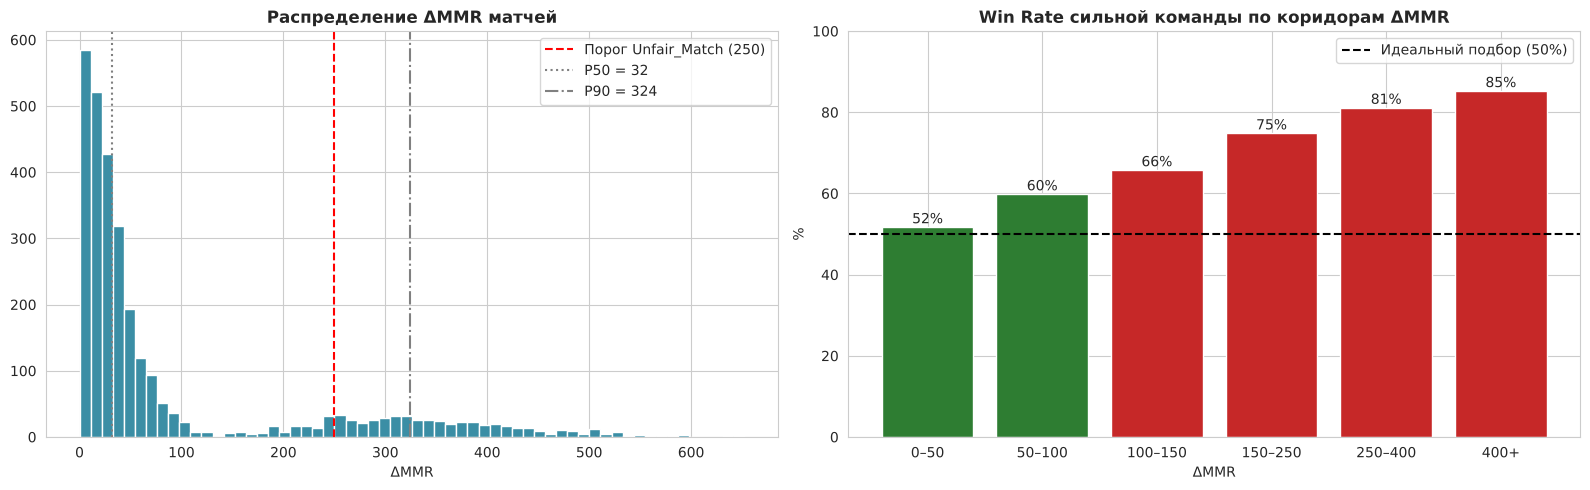

In [5]:
bins = [0, 50, 100, 150, 250, 400, np.inf]
labels = ['0–50', '50–100', '100–150', '150–250', '250–400', '400+']
mmr_analysis['delta_bin'] = pd.cut(mmr_analysis['mmr_delta'], bins=bins, labels=labels, include_lowest=True)
corridor = mmr_analysis.groupby('delta_bin', observed=True).agg(
    matches=('match_id', 'count'), stronger_win_rate=('stronger_won', 'mean'),
    avg_duration_min=('duration_sec', lambda x: x.mean() / 60))
corridor['stronger_win_rate'] *= 100
display(corridor.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(mmr_analysis['mmr_delta'], bins=60, color='#3B8EA5', edgecolor='white')
axes[0].axvline(250, color='red', linestyle='--', label='Порог Unfair_Match (250)')
for q, ls in [(0.5, ':'), (0.9, '-.')]:
    v = mmr_analysis['mmr_delta'].quantile(q)
    axes[0].axvline(v, color='gray', linestyle=ls, label=f'P{int(q * 100)} = {v:.0f}')
axes[0].set_title('Распределение ΔMMR матчей', fontweight='bold'); axes[0].set_xlabel('ΔMMR'); axes[0].legend()
axes[1].bar(corridor.index.astype(str), corridor['stronger_win_rate'],
            color=['#2E7D32' if v < 60 else '#C62828' for v in corridor['stronger_win_rate']])
axes[1].axhline(50, color='black', linestyle='--', label='Идеальный подбор (50%)')
for i, v in enumerate(corridor['stronger_win_rate']):
    axes[1].text(i, v + 1, f'{v:.0f}%', ha='center')
axes[1].set_ylim(0, 100); axes[1].set_title('Win Rate сильной команды по коридорам ΔMMR', fontweight='bold')
axes[1].set_xlabel('ΔMMR'); axes[1].set_ylabel('%'); axes[1].legend()
plt.tight_layout(); plt.savefig(f'{REPORTS}/matchmaking_quality.png', dpi=150); plt.show()

### Время поиска vs качество подбора и «паровозы»

,queue_sec,mmr_delta,unfair_share,team_std
queue_bin,,,,
"(14.999, 30.2]",24.60,127.61,0.23,275.03
"(30.2, 39.68]",35.40,112.19,0.21,259.88
"(39.68, 47.7]",43.40,117.45,0.22,249.73
"(47.7, 56.66]",52.60,104.44,0.20,238.87
"(56.66, 65.7]",61.00,90.57,0.17,236.57
"(65.7, 76.3]",71.00,84.63,0.16,222.72
"(76.3, 91.8]",84.05,71.39,0.12,215.37
"(91.8, 112.0]",100.15,81.11,0.15,189.50
"(112.0, 144.72]",125.50,73.78,0.12,175.48


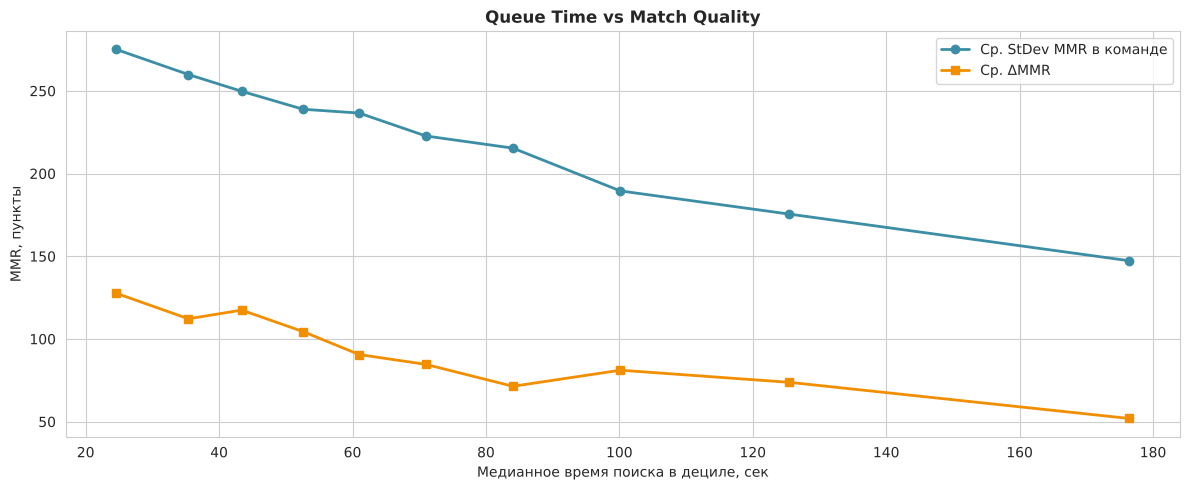

Порог «паровоза»: StDev MMR в команде > P95 = 344; таких матчей 150
Корреляция времени поиска с StDev команды: -0.51, с ΔMMR: -0.15


In [6]:
mmr_analysis['queue_bin'] = pd.qcut(mmr_analysis['queue_time_sec'], 10)
queue = mmr_analysis.groupby('queue_bin', observed=True).agg(
    queue_sec=('queue_time_sec', 'median'), mmr_delta=('mmr_delta', 'mean'),
    unfair_share=('Unfair_Match', 'mean'), team_std=('max_team_std', 'mean'))
display(queue.round(2))

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(queue['queue_sec'], queue['team_std'], marker='o', color='#3B8EA5', linewidth=2, label='Ср. StDev MMR в команде')
ax1.plot(queue['queue_sec'], queue['mmr_delta'], marker='s', color='#F18F01', linewidth=2, label='Ср. ΔMMR')
ax1.set_xlabel('Медианное время поиска в дециле, сек'); ax1.set_ylabel('MMR, пункты')
ax1.set_title('Queue Time vs Match Quality', fontweight='bold'); ax1.legend()
plt.tight_layout(); plt.savefig(f'{REPORTS}/queue_vs_quality.png', dpi=150); plt.show()

hi_std = mmr_analysis['max_team_std'].quantile(0.95)
print(f"Порог «паровоза»: StDev MMR в команде > P95 = {hi_std:.0f}; таких матчей {(mmr_analysis['max_team_std'] > hi_std).sum()}")
print(f"Корреляция времени поиска с StDev команды: {mmr_analysis[['queue_time_sec', 'max_team_std']].corr().iloc[0, 1]:.2f}, "
      f"с ΔMMR: {mmr_analysis[['queue_time_sec', 'mmr_delta']].corr().iloc[0, 1]:.2f}")

## Шаг 3. Модуль Б: баланс сторон на картах
Допустимый коридор — 48–52 % побед стороны. Если любая сторона выигрывает > 55 %, карта получает статус **Map_Disedged**. Дополнительно проверяем значимость отклонения от 50 % биномиальным тестом.

In [7]:
map_balance = (matches_df.groupby('map_id')['winning_team']
               .value_counts(normalize=True).unstack() * 100)
map_balance['matches'] = matches_df['map_id'].value_counts()
map_balance['p_value'] = [binomtest(int(round(a / 100 * n)), int(n), 0.5).pvalue
                          for a, n in zip(map_balance['Attack'], map_balance['matches'])]

def map_status(row):
    if max(row['Attack'], row['Defense']) > 55:
        return 'Map_Disedged'
    if 48 <= row['Attack'] <= 52:
        return 'Balanced'
    return 'Watch (вне 48–52%)'

map_balance['status'] = map_balance.apply(map_status, axis=1)
display(map_balance.round(3))

winning_team,Attack,Defense,matches,p_value,status
map_id,,,,,
De_Dust2,48.454,51.546,1067,0.327,Balanced
De_Inferno,39.251,60.749,721,0.000,Map_Disedged
De_Mirage,50.921,49.079,760,0.637,Balanced
De_Nuke,52.876,47.124,452,0.240,Watch (вне 48–52%)


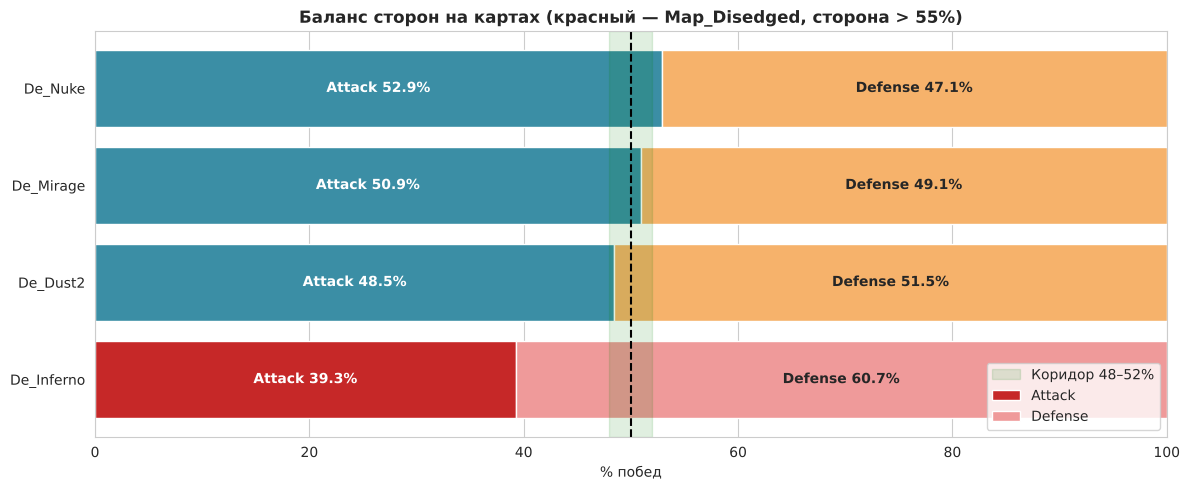

In [8]:
mb = map_balance.sort_values('Attack')
fig, ax = plt.subplots(figsize=(12, 5))
att_colors = ['#C62828' if s == 'Map_Disedged' else '#3B8EA5' for s in mb['status']]
def_colors = ['#EF9A9A' if s == 'Map_Disedged' else '#F6B26B' for s in mb['status']]
ax.barh(mb.index, mb['Attack'], color=att_colors, label='Attack')
ax.barh(mb.index, mb['Defense'], left=mb['Attack'], color=def_colors, label='Defense')
for i, (a, d) in enumerate(zip(mb['Attack'], mb['Defense'])):
    ax.text(a / 2, i, f'Attack {a:.1f}%', ha='center', va='center', color='white', fontweight='bold')
    ax.text(a + d / 2, i, f'Defense {d:.1f}%', ha='center', va='center', fontweight='bold')
ax.axvline(50, color='black', linestyle='--'); ax.axvspan(48, 52, color='green', alpha=0.12, label='Коридор 48–52%')
ax.set_xlim(0, 100); ax.set_xlabel('% побед')
ax.set_title('Баланс сторон на картах (красный — Map_Disedged, сторона > 55%)', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(f'{REPORTS}/map_balance.png', dpi=150); plt.show()

### Чистый Win Rate элементов меты (без зеркальных матчей)

In [9]:
pm = players_df.merge(matches_df[['match_id', 'winning_team', 'map_id', 'duration_sec']], on='match_id')
pm['win'] = (pm['team_side'] == pm['winning_team']).astype(int)

def clean_win_rate(df, item_col):
    # Зеркальный матч: элемент присутствует у обеих команд
    df = df.copy()
    df['is_mirror'] = df.groupby(['match_id', item_col])['team_side'].transform('nunique') > 1
    # Учитываем один раз на команду (если элемент у двух игроков одной команды)
    per_team = df.drop_duplicates(['match_id', 'team_side', item_col])
    total_matches = df['match_id'].nunique()
    res = per_team.groupby(item_col).agg(matches=('match_id', 'nunique'), raw_win_rate=('win', 'mean'))
    clean = per_team[~per_team['is_mirror']].groupby(item_col).agg(
        clean_matches=('match_id', 'nunique'), clean_win_rate=('win', 'mean'))
    res = res.join(clean)
    res['pick_rate'] = res['matches'] / total_matches * 100
    res['mirror_share'] = 1 - res['clean_matches'] / res['matches']
    res[['raw_win_rate', 'clean_win_rate']] *= 100
    return res.sort_values('pick_rate', ascending=False)

weapon_wr = clean_win_rate(pm, 'weapon_id')
print("Оружие (чистый Win Rate):")
display(weapon_wr.round(2))

Оружие (чистый Win Rate):


,matches,raw_win_rate,clean_matches,clean_win_rate,pick_rate,mirror_share
weapon_id,,,,,,
Shotgun_Nova,2528,50.44,1460,51.10,84.27,0.42
Rifle_M4,2521,49.94,1446,49.86,84.03,0.43
Sniper_AWP,2521,49.71,1431,49.27,84.03,0.43
Rifle_AK,2507,49.66,1444,49.17,83.57,0.42
SMG_MP9,2489,50.06,1430,50.14,82.97,0.43
Pistol_Deagle,2471,50.48,1414,51.20,82.37,0.43


## Шаг 4. Модуль В: антифрод и контроль токсичности
* **K/D Ratio** = Kills / Deaths (при Deaths = 0 делим на 1);
* новички (< 15 матчей) не оцениваются — выборка мала;
* средний **K/D > 4.5** → статус **Sent_to_Overwatch** (ручная модерация);
* **Report Density** — жалобы на 100 сыгранных минут.

In [10]:
pm['kd_ratio'] = pm['kills'] / np.where(pm['deaths'] == 0, 1, pm['deaths'])
pm['minutes'] = pm['duration_sec'] / 60

received = reports_df.groupby(['reported_id', 'reason']).size().unstack(fill_value=0)
received['reports_total'] = received.sum(axis=1)

profile = pm.groupby('player_id').agg(
    matches=('match_id', 'nunique'), avg_kd=('kd_ratio', 'mean'),
    total_kills=('kills', 'sum'), total_deaths=('deaths', 'sum'),
    minutes_played=('minutes', 'sum'), avg_mmr=('mmr_before', 'mean'), win_rate=('win', 'mean'))
profile['weighted_kd'] = profile['total_kills'] / profile['total_deaths'].clip(lower=1)
profile = profile.join(received, how='left').fillna({c: 0 for c in received.columns})
profile['report_density'] = profile['reports_total'] / profile['minutes_played'] * 100

veterans = profile[profile['matches'] >= 15].copy()
veterans['clearance_status'] = np.where(veterans['avg_kd'] > 4.5, 'Sent_to_Overwatch', 'Clear')

print(f"Игроков всего: {len(profile):,}; со стажем ≥ 15 матчей: {len(veterans):,}")
print(f"Отправлено на Overwatch (K/D > 4.5): {(veterans['clearance_status'] == 'Sent_to_Overwatch').sum()}")
print(f"Медианный K/D игроков со стажем: {veterans['avg_kd'].median():.2f}; "
      f"медианная плотность жалоб: {veterans['report_density'].median():.3f} на 100 минут")

Игроков всего: 1,953; со стажем ≥ 15 матчей: 843
Отправлено на Overwatch (K/D > 4.5): 15
Медианный K/D игроков со стажем: 1.24; медианная плотность жалоб: 0.071 на 100 минут


In [11]:
# Дополнительные правила: смурфы и токсичность
tox_thr = veterans['toxicity'].div(veterans['minutes_played']).mul(100).quantile(0.97)
veterans['toxicity_density'] = veterans['toxicity'] / veterans['minutes_played'] * 100
veterans['flag_smurf'] = (veterans['avg_kd'].between(2.5, 4.5)) & (veterans['avg_mmr'] < 1600)
veterans['flag_toxic'] = veterans['toxicity_density'] > max(tox_thr, 0.5)

ban_candidates = (veterans[(veterans['clearance_status'] == 'Sent_to_Overwatch') | veterans['flag_smurf'] | veterans['flag_toxic']]
                  .assign(reason_flag=lambda d: np.select(
                      [d['clearance_status'] == 'Sent_to_Overwatch', d['flag_smurf'], d['flag_toxic']],
                      ['Cheating (K/D > 4.5)', 'Smurf (высокий K/D при низком MMR)', 'Toxicity'], 'Other'))
                  .sort_values(['avg_kd', 'reports_total'], ascending=False))
cols = ['matches', 'avg_kd', 'weighted_kd', 'avg_mmr', 'reports_total', 'cheating', 'toxicity',
        'report_density', 'reason_flag']
print("Кандидаты на проверку/бан (сортировка по K/D и числу жалоб):")
display(ban_candidates[cols].round(2).head(20))
print(ban_candidates['reason_flag'].value_counts())
ban_candidates[cols].round(3).to_csv(f'{REPORTS}/ban_candidates.csv', encoding='utf-8-sig')

Кандидаты на проверку/бан (сортировка по K/D и числу жалоб):


,matches,avg_kd,weighted_kd,avg_mmr,reports_total,cheating,toxicity,report_density,reason_flag
player_id,,,,,,,,,
PLAYER_00427,93,24.90,20.53,2299.57,142.0,142.0,0.0,5.19,Cheating (K/D > 4.5)
PLAYER_00131,22,24.27,20.74,1812.05,29.0,28.0,0.0,4.90,Cheating (K/D > 4.5)
PLAYER_01412,74,24.15,20.54,2780.74,120.0,119.0,1.0,5.64,Cheating (K/D > 4.5)
PLAYER_01214,38,24.05,21.54,2054.18,61.0,61.0,0.0,5.71,Cheating (K/D > 4.5)
PLAYER_00074,38,22.51,18.66,2935.37,57.0,57.0,0.0,5.62,Cheating (K/D > 4.5)
PLAYER_00523,33,22.43,17.84,2298.61,41.0,41.0,0.0,4.42,Cheating (K/D > 4.5)
PLAYER_00706,76,22.12,17.25,2562.83,113.0,112.0,1.0,5.38,Cheating (K/D > 4.5)
PLAYER_01637,32,21.28,17.15,2573.22,49.0,49.0,0.0,5.77,Cheating (K/D > 4.5)
PLAYER_00704,33,20.56,15.83,1961.67,51.0,51.0,0.0,5.58,Cheating (K/D > 4.5)


reason_flag
Toxicity                              16
Cheating (K/D > 4.5)                  15
Smurf (высокий K/D при низком MMR)    10
Name: count, dtype: int64


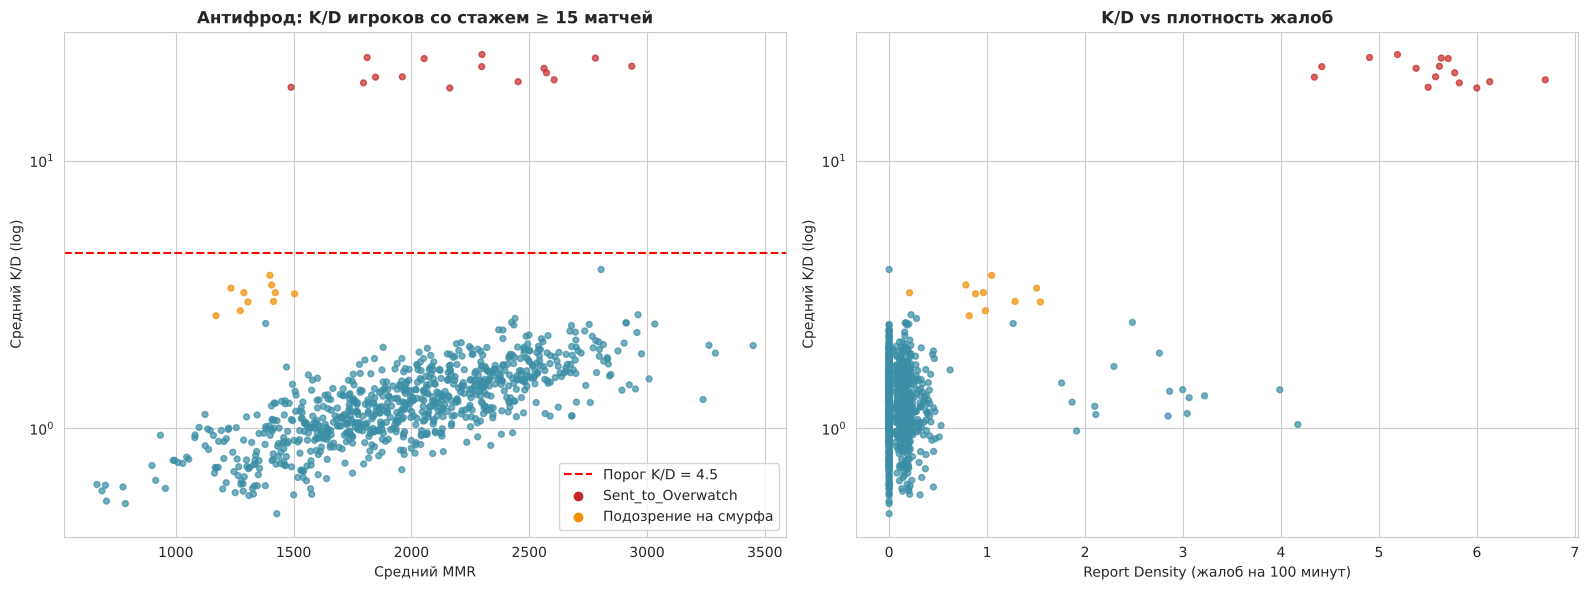

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = veterans['clearance_status'].map({'Sent_to_Overwatch': '#C62828', 'Clear': '#3B8EA5'})
colors[veterans['flag_smurf']] = '#F18F01'
axes[0].scatter(veterans['avg_mmr'], veterans['avg_kd'], c=colors, s=18, alpha=0.7)
axes[0].axhline(4.5, color='red', linestyle='--', label='Порог K/D = 4.5')
axes[0].set_yscale('log'); axes[0].set_xlabel('Средний MMR'); axes[0].set_ylabel('Средний K/D (log)')
axes[0].set_title('Антифрод: K/D игроков со стажем ≥ 15 матчей', fontweight='bold')
axes[0].scatter([], [], c='#C62828', label='Sent_to_Overwatch'); axes[0].scatter([], [], c='#F18F01', label='Подозрение на смурфа')
axes[0].legend()
axes[1].scatter(veterans['report_density'], veterans['avg_kd'], c=colors, s=18, alpha=0.7)
axes[1].set_yscale('log'); axes[1].set_xlabel('Report Density (жалоб на 100 минут)'); axes[1].set_ylabel('Средний K/D (log)')
axes[1].set_title('K/D vs плотность жалоб', fontweight='bold')
plt.tight_layout(); plt.savefig(f'{REPORTS}/antifraud.png', dpi=150); plt.show()

### Валидация антифрода по скрытой разметке (`ground_truth.csv`)

In [13]:
truth = pd.read_csv('../data/ground_truth.csv').set_index('player_id')
v = veterans.join(truth['player_type'])
print("Sent_to_Overwatch × истинный тип:")
display(pd.crosstab(v['clearance_status'], v['player_type'], margins=True))
print("Флаг смурфа × истинный тип:")
display(pd.crosstab(v['flag_smurf'], v['player_type']))
print("Флаг токсичности × истинный тип:")
display(pd.crosstab(v['flag_toxic'], v['player_type']))
cheat_all = (truth['player_type'] == 'cheater').sum()
caught = ((v['clearance_status'] == 'Sent_to_Overwatch') & (v['player_type'] == 'cheater')).sum()
print(f"Поймано читеров: {caught} из {cheat_all}; ложных срабатываний: "
      f"{((v['clearance_status'] == 'Sent_to_Overwatch') & (v['player_type'] != 'cheater')).sum()}")

Sent_to_Overwatch × истинный тип:


player_type,cheater,normal,smurf,toxic,All
clearance_status,,,,,
Clear,0,801,11,16,828
Sent_to_Overwatch,15,0,0,0,15
All,15,801,11,16,843


Флаг смурфа × истинный тип:


player_type,cheater,normal,smurf,toxic
flag_smurf,,,,
False,15,801,1,16
True,0,0,10,0


Флаг токсичности × истинный тип:


player_type,cheater,normal,smurf,toxic
flag_toxic,,,,
False,15,801,11,0
True,0,0,0,16


Поймано читеров: 15 из 15; ложных срабатываний: 0


### Шаг 5. Экспорт витрин для дашборда

In [14]:
mmr_analysis.drop(columns=['delta_bin', 'queue_bin']).to_csv(f'{REPORTS}/mart_matchmaking.csv', index=False)
map_balance.to_csv(f'{REPORTS}/mart_map_balance.csv', encoding='utf-8-sig')
veterans.to_csv(f'{REPORTS}/mart_player_security.csv', encoding='utf-8-sig')
print("Сохранено: mart_matchmaking.csv, mart_map_balance.csv, mart_player_security.csv, ban_candidates.csv")

Сохранено: mart_matchmaking.csv, mart_map_balance.csv, mart_player_security.csv, ban_candidates.csv
